# Tarea 26: Clustering jerárquico

In [26]:
# load libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import normalize

# libraries for clustering 
import scipy.cluster.hierarchy as sch

from scipy.cluster.hierarchy import fcluster
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score)



In [3]:
# load amazon data from excel file
df = pd.read_excel('Amazon.xlsx')
df.sample(5)

,Unnamed: 0,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
91,Sylvan,24,85,38,21,33,14,29,275,24
59,Maria,115,225,4,235,33,22,435,25,35
5,Fabian,95,165,395,24,26,19,485,22,3
18,Eunice,265,7,485,305,33,39,34,295,39
34,Ivan,12,5,385,17,17,11,31,205,2


In [4]:
# normalize values 
df_numeric = df.drop(columns= ['Unnamed: 0'])
data_scaled = normalize(df_numeric)
df_scaled = pd.DataFrame(data_scaled, columns=df.columns.drop('Unnamed: 0'))
df_scaled.sample(5)

,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
73,0.038143,0.095357,0.667500,0.330082,0.048412,0.039610,0.535467,0.374093,0.066016
21,0.036538,0.004299,0.891945,0.268658,0.025791,0.036538,0.055881,0.354629,0.004299
28,0.314140,0.025131,0.888566,0.314140,0.055648,0.030516,0.048467,0.048467,0.061033
5,0.144940,0.251738,0.602646,0.036616,0.039668,0.028988,0.739957,0.033565,0.004577
20,0.386348,0.105368,0.100685,0.004683,0.049172,0.042147,0.737573,0.526838,0.060879


## Búsqueda del número de cluster óptimo

La búsqueda del cluster óptimo se realiza con el cálculo y comparación de salto de distancias, métricas (silueta, Calinski-Harabasz, Davies-Bouldin) con diferentes valores entre 2 y 10, y salto de dendrograma para evaluar cual es el número de cluster optimo. 

| Enfoque| Base matemática | Ventaja | Desventaja | 
|----------|----------|----------|----------|
| Salto de distancias | Monotonía de las fusiones: las distancias crecen al subir el árbol | Coincide con la intuición visual del dendrograma, y es rápido de calcular  | Muy sensible al método de linkage y a la métrica de la distancia, no considera la calidad interna de los grupos | 
| Silueta | $s(i)=\frac{b(i)−a(i)}{max(a(i),b(i))}$ ​ Distancias intra vs inter - cluster | Robusto, rango acotado | Costo computacional alto $O(n^2)$ | 
| Calinski-Harabasz | $CH=\frac{tr(B_k)/(k-1)}{tr(W_k)/(n-1)}$  varianza entre/dentro | Rápido computacionalmente $O(n)$, favorece grupos compactos y bien separados  | Sesgado en k pequeños, no acotado |
| Davies-Bouldin | Similitud promedio entre cada cluster y su vecino mas similar | Penaliza solapamiento, bajo = mejor, rápido de calcular | Sensible a outliers |
| `distance_threshold` | Altura de corte del dendrograma | Directo en scipy/sklearn | Requiere elegir el umbral, la altura optima depende del escalado y linkage |


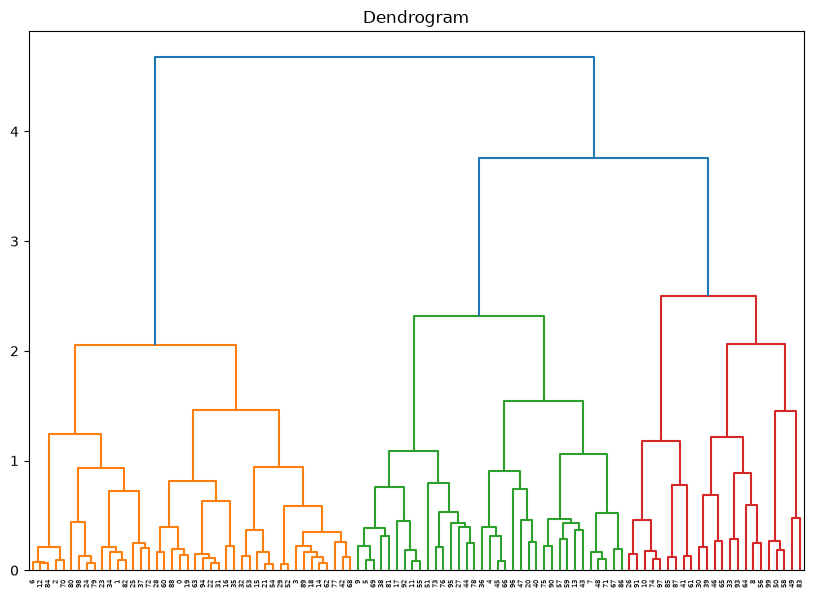

In [5]:
Z = sch.linkage(df_scaled, method='ward')
plt.figure(figsize=(10, 7))
plt.title('Dendrogram')
dend = sch.dendrogram(Z)


En el primer dendograma, mostrado en la gráfica, visualmente se puede decir que el numero de cluster optimo es 3, pero esto no es una justificación técnica robusto.

### Método del salto

En este método se toman las ultimas 10 distancias de fusion (las mas grandes) de Z, se calcula el gap y se busca indice del mayor, para finalmente mostrar el k o numero de clusters optimo

In [22]:
last = Z[-10:, 2]  # fusion distances 
gap = np.diff(last) # calculus of the gap
step_idx = np.argmax(gap) 

cut_distance = (last[step_idx] + last[step_idx + 1]) /2
k_optimal_step = len(last) - step_idx
print(f'Fusion distances: {np.round(last, 2)}')
print(f'Gap: {np.round(gap, 2)}')
print(f'Max index step {step_idx} -> k suggested = {k_optimal_step}')
print(f'Cut distance = {cut_distance:.3f}')

Fusion distances: [1.24 1.45 1.46 1.54 2.05 2.06 2.32 2.5  3.76 4.68]
Gap: [0.21 0.01 0.08 0.51 0.01 0.26 0.18 1.26 0.92]
Max index step 7 -> k suggested = 3
Cut distance = 3.127


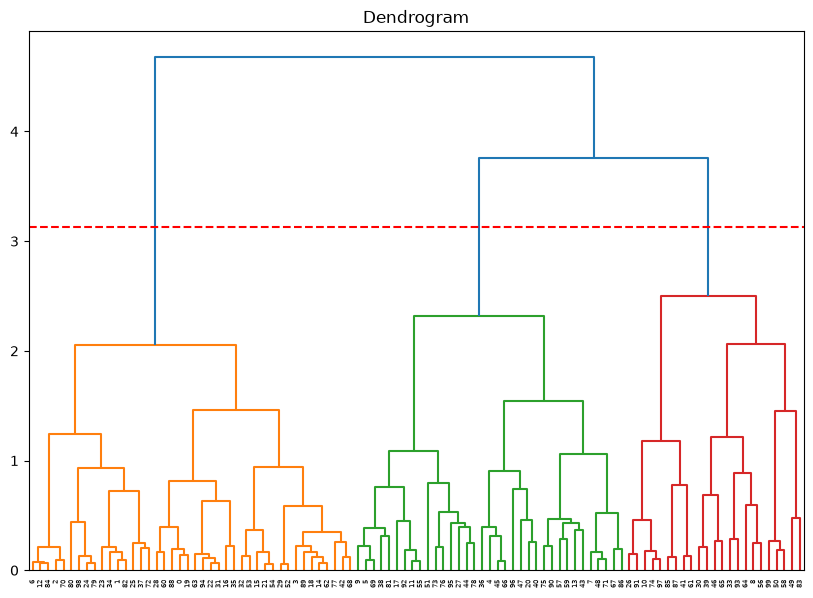

In [25]:
plt.figure(figsize=(10, 7))
plt.title('Dendrogram')
dendrogram = sch.dendrogram(Z, color_threshold= cut_distance)

plt.axhline(y = cut_distance, color = 'r', linestyle = '--')
plt.show()

Los resultados con el método de corte muestran los siguiente:
- La linea de corte es determinada por la línea roja punteada en la gráfica anterior con valor de $y~3$
- Este método recomienda 3 clusters para el data set con el que se trabajo
- Visualmente se pueden corroborar cluster por los colores muestra el dendograma

### Análisis de métricas para seleccionar el cluster óptimo

In [33]:
results = []

for k in range(2, 11):
    labels = fcluster(Z, t= k, criterion='maxclust') # it selects maxclust option because it defines the k numbers first
    sil = silhouette_score(df_scaled, labels)
    ch = calinski_harabasz_score(df_scaled, labels)
    db = davies_bouldin_score(df_scaled, labels)
    results.append((
        k,
        sil,
        ch, 
        db
    )) 
    print(f"k={k:2d} | Silueta={sil:.4f} | Calinski-Harabasz={ch:8.2f} | Davies-Bouldin={db:.4f}")


k= 2 | Silueta=0.2486 | Calinski-Harabasz=   35.19 | Davies-Bouldin=1.5074
k= 3 | Silueta=0.3039 | Calinski-Harabasz=   37.28 | Davies-Bouldin=1.4766
k= 4 | Silueta=0.3135 | Calinski-Harabasz=   33.28 | Davies-Bouldin=1.3026
k= 5 | Silueta=0.2838 | Calinski-Harabasz=   32.11 | Davies-Bouldin=1.2788
k= 6 | Silueta=0.3045 | Calinski-Harabasz=   31.51 | Davies-Bouldin=1.1685
k= 7 | Silueta=0.2875 | Calinski-Harabasz=   32.50 | Davies-Bouldin=1.2223
k= 8 | Silueta=0.2910 | Calinski-Harabasz=   31.54 | Davies-Bouldin=1.2024
k= 9 | Silueta=0.2887 | Calinski-Harabasz=   30.99 | Davies-Bouldin=1.1743
k=10 | Silueta=0.2996 | Calinski-Harabasz=   31.12 | Davies-Bouldin=1.0633


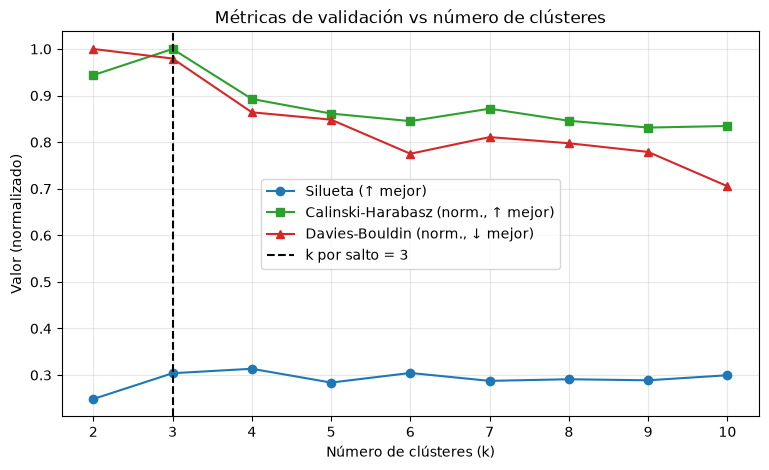

In [32]:
res = np.array(results)
fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(res[:,0], res[:,1], 'o-', color='tab:blue', label='Silueta (↑ mejor)')
ax1.plot(res[:,0], res[:,2]/max(res[:,2]), 's-', color='tab:green',
         label='Calinski-Harabasz (norm., ↑ mejor)')
ax1.plot(res[:,0], res[:,3]/max(res[:,3]), '^-', color='tab:red',
         label='Davies-Bouldin (norm., ↓ mejor)')
ax1.set_xlabel("Número de clústeres (k)")
ax1.set_ylabel("Valor (normalizado)")
ax1.axvline(x=k_optimal_step, color='black', linestyle='--',
            label=f'k por salto = {k_optimal_step}')
ax1.legend()
ax1.set_title("Métricas de validación vs número de clústeres")
plt.grid(alpha=0.3)
plt.show()


En términos generales la estructura es débil, por lo siguiente:
- Silueta: el maximo $k=4$, pero $k=3$ y $k=6$ son similares
- Calinski-Harabasz: el maximo es  $k=3 (37.28)$
- Davies-Bouldin: Baja monotonamente respecto a $k$ y el minimo es $k=10$, significa que mejora en clusters mas pequenos 

El valor $k=3$ coincide con el salto maximo del dendrogramay el maximo valor de Calinski-Harabasz
El valor $k=4$ tiene la mejor silueta

La opcion mas coherente, es decir, valor optimo del numero de clusters es $k=3$. Peor si se busca mas detalle usar $k=4$.

### Dendrograma final con el número óptimo de clusters $k=3$

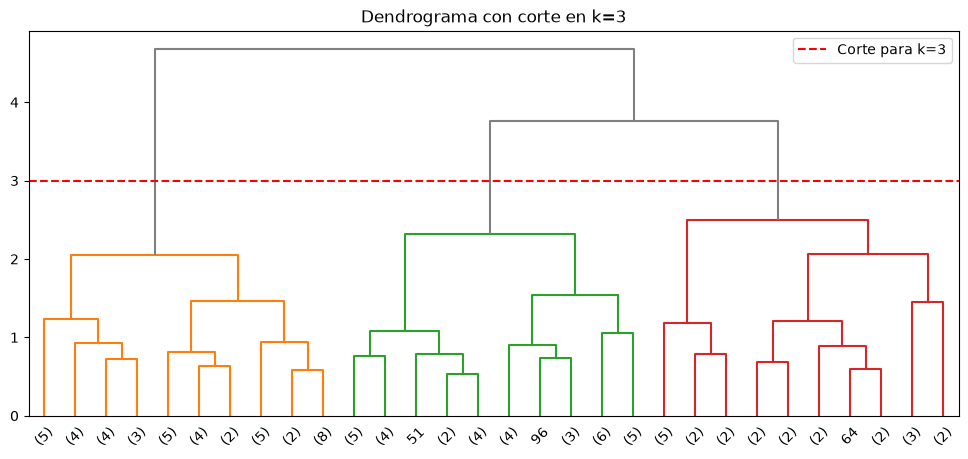

In [40]:
k_final = 3  
plt.figure(figsize=(12, 5))
sch.dendrogram(Z, truncate_mode='lastp', color_threshold=Z[-(k_final-1), 2],above_threshold_color='gray')
plt.axhline(y=k_final, color='red', linestyle='--', label=f'Corte para k={k_final}')
plt.legend()
plt.title(f"Dendrograma con corte en k={k_final}")
plt.show()


# Descripción de los perfiles de cada cluster 

Primero se agregara una nueva columna al dataframe inicial para asignar a cada usuario un cluster. Esto se hace con `AgglomerativeClustering`, que permite crear las etiquetas segun la informacion en los datos, previamente escalados, y uno de sus parametros principales es el numero de clusters, que se justifico anteriormente como $k=3$ .

In [41]:
from sklearn.cluster import AgglomerativeClustering
number_of_optimal_cluster = 3
cluster = AgglomerativeClustering(n_clusters=number_of_optimal_cluster, metric = 'euclidean', linkage= 'ward')
labels = cluster.fit_predict(data_scaled)

df['Cluster'] = labels

# Gráfica de velocidad de entrega vs. número de estrellas  

Para visualizar como es la clusterización de las variables, se graficá con `Seaborn` los pares de variables. 

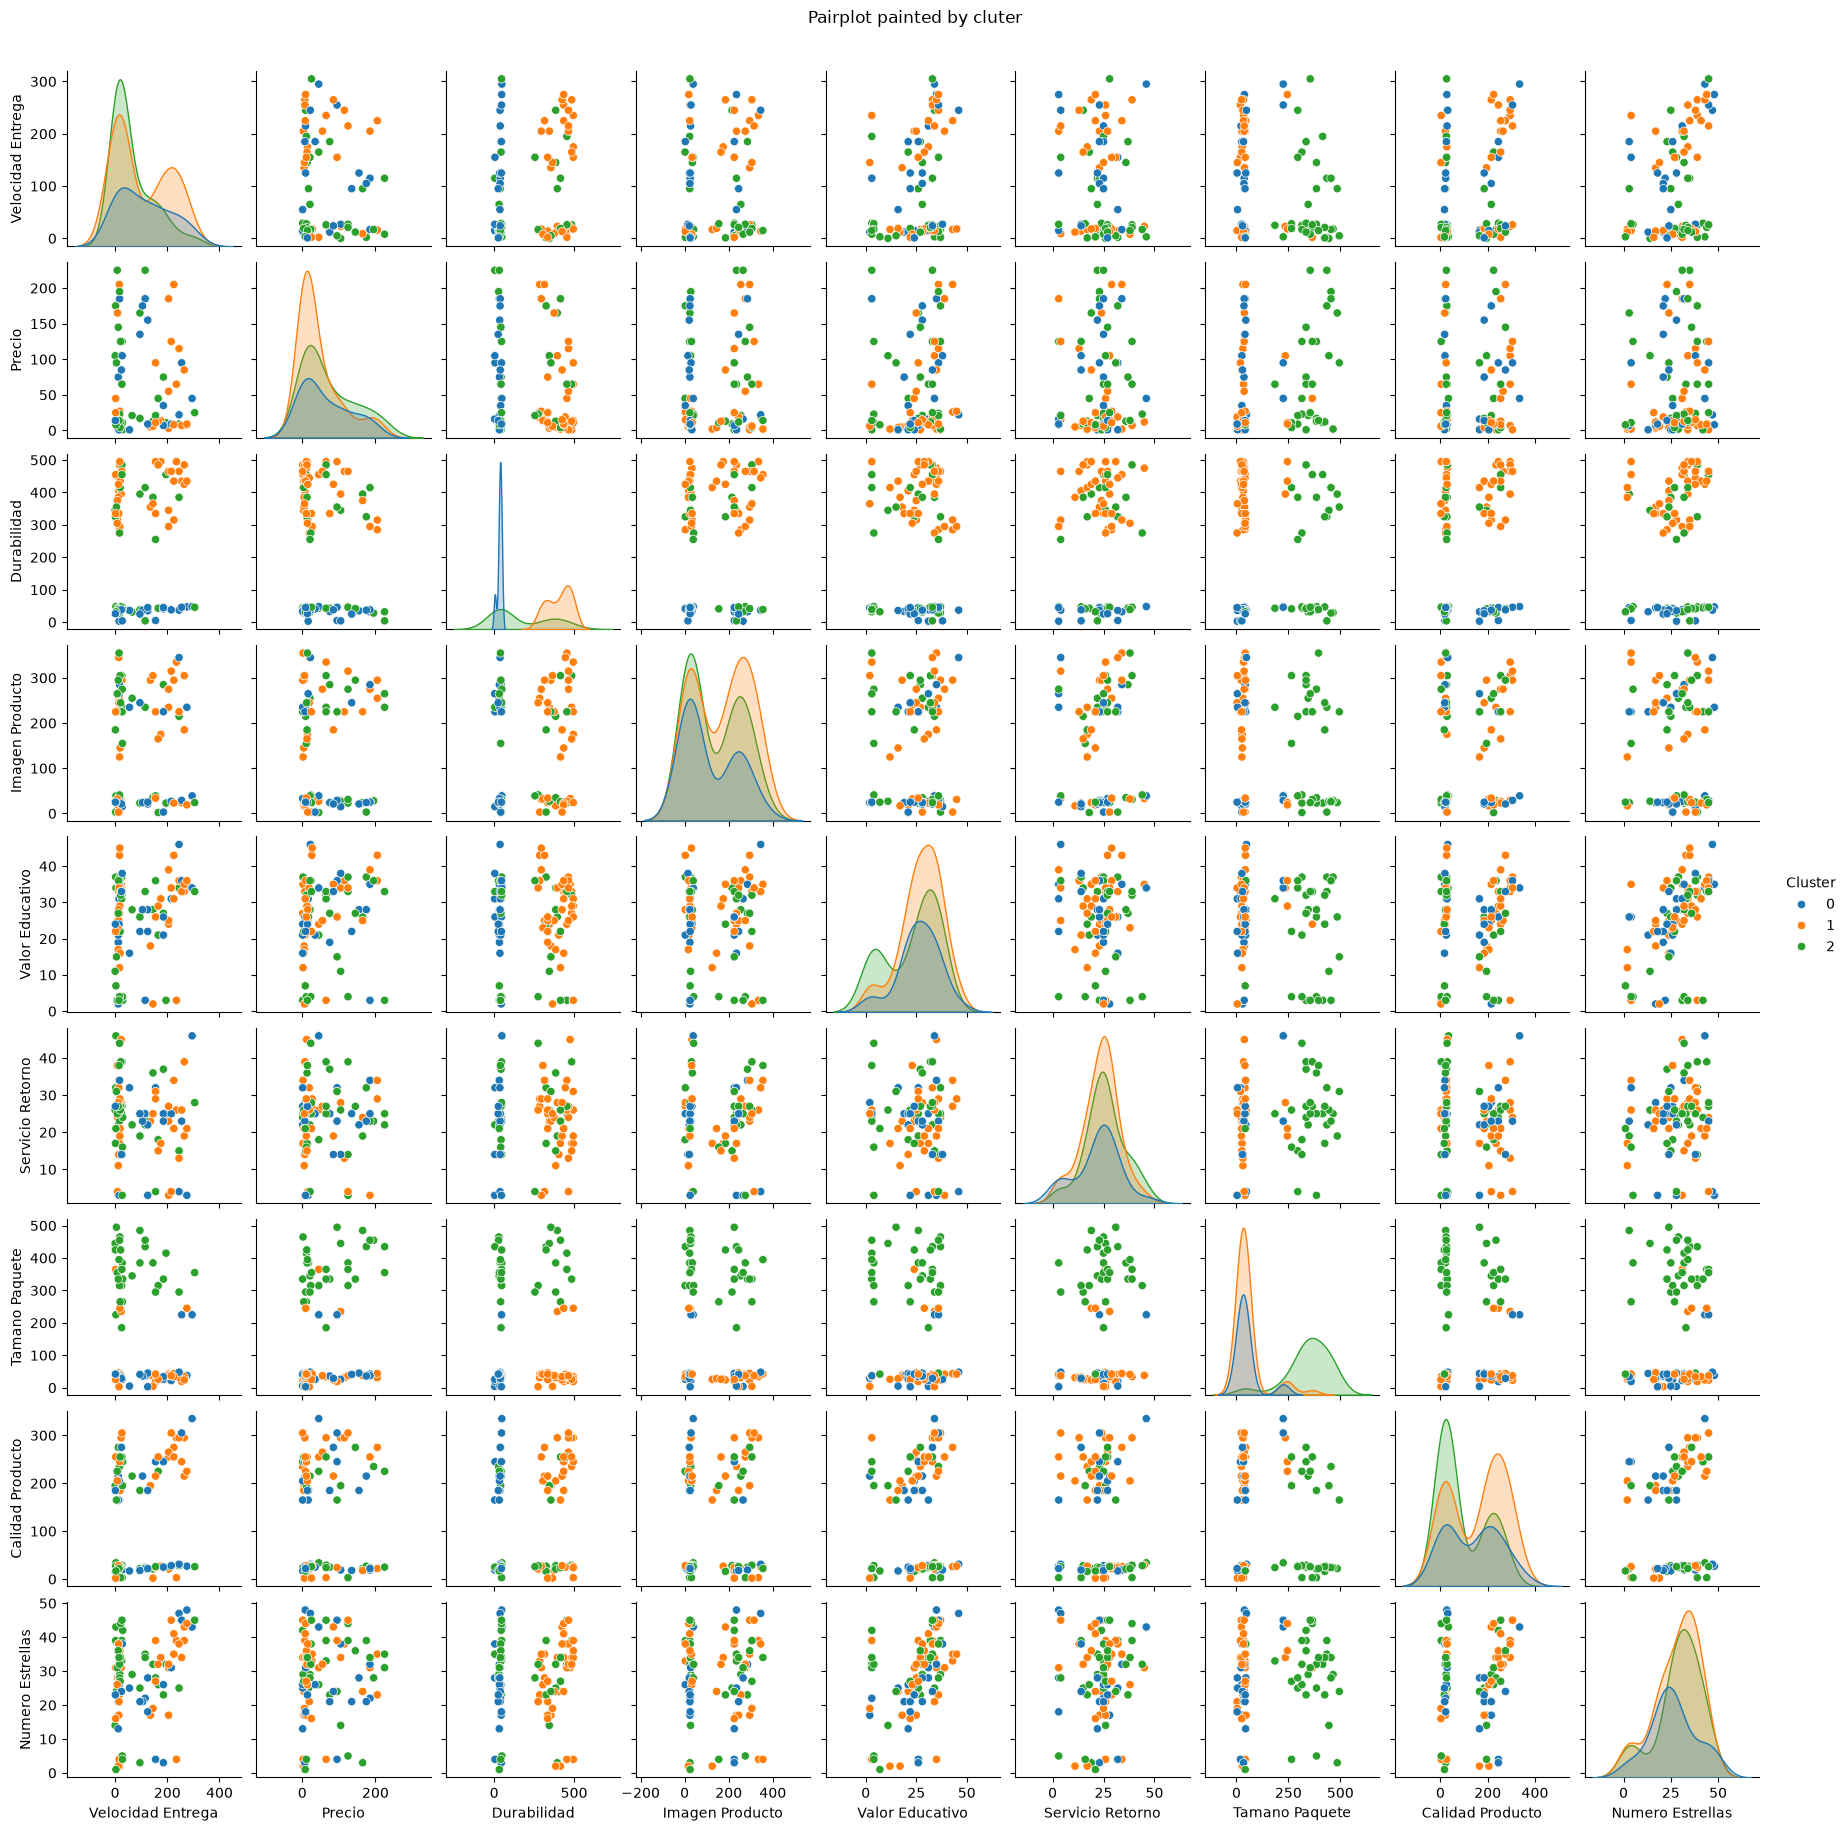

In [42]:
import seaborn as sns

sns.pairplot(df, hue='Cluster', palette='tab10', diag_kind='kde', corner=False, height=2)
plt.suptitle('Pairplot painted by cluter', y = 1.02)
plt.show()

En los gráficas de pares de variables, se pueden ver que los clusters que muestran  mayor separación son tamaño de paquete respecto a las demás variables.

# Gráfica de Reducción de dimencionalidad PCA

In [44]:
from sklearn import decomposition

pca = decomposition.PCA(n_components=2)
pca.fit(data_scaled)
campos = pca.transform(data_scaled)
campos

array([[ 0.39993219, -0.06035374],
       [ 0.40829583,  0.06402268],
       [ 0.49703182,  0.35955286],
       [ 0.33996675, -0.18434501],
       [-0.58207751,  0.38797653],
       [-0.1723403 ,  0.52962573],
       [ 0.56528441,  0.33770585],
       [-0.5335887 , -0.06994712],
       [-0.09981604, -0.47165743],
       [-0.22195207,  0.56503313],
       [-0.08274005, -0.39712712],
       [ 0.00143465,  0.48936583],
       [ 0.57292039,  0.35927774],
       [-0.51350639, -0.01301312],
       [ 0.35272162, -0.20639728],
       [ 0.4688626 , -0.0168001 ],
       [ 0.25142488, -0.04599019],
       [ 0.05456876,  0.22302796],
       [ 0.36123131, -0.20553368],
       [ 0.41087067, -0.02173183],
       [-0.54207892,  0.03308916],
       [ 0.5138909 ,  0.0900875 ],
       [ 0.4284552 ,  0.0601418 ],
       [ 0.42320562,  0.09945498],
       [ 0.42610215, -0.06318626],
       [ 0.10615885,  0.20376697],
       [-0.19058214, -0.3966612 ],
       [ 0.096838  ,  0.33104612],
       [ 0.51505714,

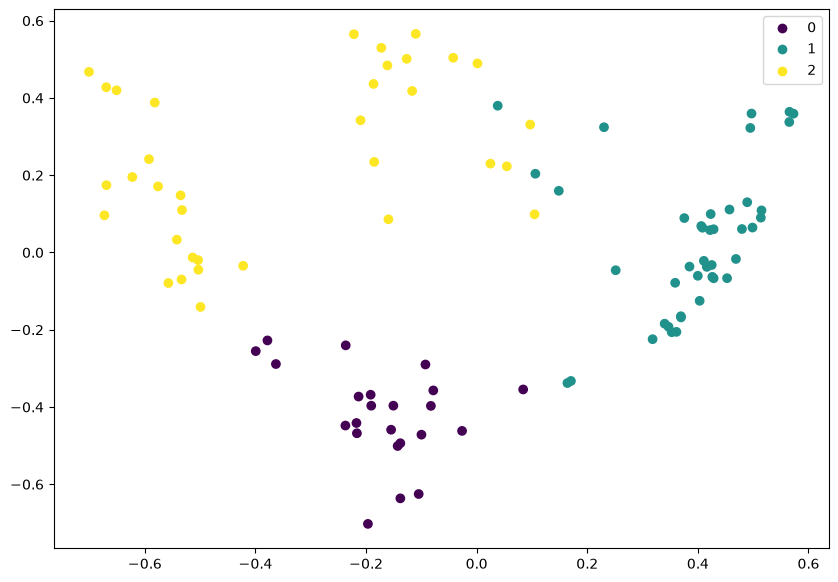

In [75]:
plt.figure(figsize=(10, 7))
scatter = plt.scatter(campos[:,0], campos[:,1], c = cluster.labels_ )
plt.legend(*scatter.legend_elements())

La reducción de dimensionalidad para lograr visualizar los clusters de una forma mas general.

## Recomendaciones por cluster

A continuación se resumen las características de los clusters y después se hacen varas recomendaciones a personas a traves del cluster al que pertenecen. También se calcula el coeficiente de variación (CV) para cada variable. 

In [64]:
cluster_description = df_scaled
cluster_description['Cluster'] = labels
cluster_description = df_scaled.groupby('Cluster').mean()
cluster_description


,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
Cluster,,,,,,,,,
0,0.369451,0.236988,0.124698,0.356054,0.096870,0.081379,0.147607,0.462479,0.099031
1,0.178815,0.085323,0.782477,0.306863,0.055366,0.047294,0.102124,0.287885,0.055432
2,0.129802,0.146588,0.327101,0.279015,0.059385,0.066706,0.712248,0.188812,0.069958


Cluster 0:
- Tiene mejor velocidad de entrega, mayor precio, mejor imagen del producto, mayor valor educativo, mayor servicio de retorno, mejor calidad del producto y es el mejor evaluado.

Cluster 1: 
- Tiene el menor precio, mas durabilidad, menor valor educativo, el menor servicio de retorno, menor tamaño de paquete y menor numero de estrellas

Cluster 2:
- Tiene la menor calidad de producto.

In [65]:
cluster_description.describe()

,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
count,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
mean,0.226023,0.156299,0.411425,0.313977,0.070540,0.065126,0.320660,0.313059,0.074807
std,0.126607,0.076297,0.336899,0.039009,0.022891,0.017097,0.339887,0.138559,0.022200
min,0.129802,0.085323,0.124698,0.279015,0.055366,0.047294,0.102124,0.188812,0.055432
25%,0.154308,0.115955,0.225900,0.292939,0.057375,0.057000,0.124865,0.238349,0.062695
50%,0.178815,0.146588,0.327101,0.306863,0.059385,0.066706,0.147607,0.287885,0.069958
75%,0.274133,0.191788,0.554789,0.331458,0.078128,0.074043,0.429928,0.375182,0.084494
max,0.369451,0.236988,0.782477,0.356054,0.096870,0.081379,0.712248,0.462479,0.099031


In [67]:
# Calculus of variation coeficient cv = sigma / mean
cv_decimal = ( cluster_description.std() / cluster_description.mean() ) * 100
cv_decimal

Velocidad Entrega     56.015289
Precio                48.814726
Durabilidad           81.885853
Imagen Producto       12.424148
Valor Educativo       32.450437
Servicio Retorno      26.252631
Tamano Paquete       105.996241
Calidad Producto      44.259888
Numero Estrellas      29.676652
dtype: float64

De las variables podemos ver lo siguiente:

- Como se vio en las gráficas en el tamaño del paquete es donde se ve mas definición en los cluster, esta variable tiene un coeficiente de alto comparado con las demás
- Las variables con coeficientes de variabilidad mas bajos $<30$ son el Valor educativo, las imagen del producto, y el numero de estrellas
- Las variables con coeficiente de variabilidad mas alto  $>50$ son las velocidad de entrega, la durabilidad y tamaño de paquete, 

## Productos recomendados a Salome

In [68]:
cluster_salome = df[df['Unnamed: 0']=='Salome']['Cluster'].values[0]

clients_with_same_cluster = df[df['Cluster'] == cluster_salome]  
print(f'El cluster {cluster_salome} son los productos recomendados a Salome, quien ya compraron ese tipo de productos son:')
print(clients_with_same_cluster['Unnamed: 0'])

El cluster 2 son los productos recomendados a Salome, quien ya compraron ese tipo de productos son:
4        Emilia
5        Fabian
7         Frank
9       Gabriel
11        Henry
13     Isabelle
17      Eugenia
20      Evdokia
27     Florence
36     Jeremiah
38      Joachim
40     Santiago
43       Justin
44       Kalyna
45      Larissa
47         Leon
48      Leonard
51          Leo
55    Magdalyna
57       Marcel
59        Maria
66       Maryna
67      Matthew
69         Maya
71      Melania
73      Michael
75         Mina
76       Monica
78        Myron
81       Salome
86    Sebastian
90      Susanna
92    Sylvester
95       Teofan
96       Teofil
Name: Unnamed: 0, dtype: str


## Productos recomendados a Stephania

In [69]:
cluster_stephania = df[df['Unnamed: 0']=='Stephania']['Cluster'].values[0]

clients_with_same_cluster = df[df['Cluster'] == cluster_stephania]  
print(f'El cluster {cluster_stephania} son los productos recomendados a Stephania, quien ya compraron ese tipo de productos son:')
print(clients_with_same_cluster['Unnamed: 0'])

El cluster 1 son los productos recomendados a Stephania, quien ya compraron ese tipo de productos son:
0            Adam
1            Anna
2         Bernard
3          Edward
6          Philip
12          Irene
14        Isidore
15         Joseph
16         Eugene
18         Eunice
19            Eva
21          Fedir
22          Felix
23         Fialka
24         Flavia
25          Flora
28         Hannah
29          Helen
31         Hilary
32        Lourdes
34           Ivan
35          Jacob
37         Jervis
42         Judith
52         Louise
53        Lubomyr
54          Lydia
60         Marian
62        Markian
63          Marko
68          Maura
70    Maximillian
72      Methodius
77         Mykyta
79       Myroslav
80      Myroslava
82         Samuel
84          Sarah
88        Stephan
89      Stephania
94       Theodore
98           Teon
Name: Unnamed: 0, dtype: str


## Productos recomendados a Lydia

In [70]:
## Productos recomendados a Lydia
cluster_lydia = df[df['Unnamed: 0']=='Lydia']['Cluster'].values[0]

clients_with_same_cluster = df[df['Cluster'] == cluster_lydia]  
print(f'El cluster {cluster_lydia} son los productos recomendados a Lydia, quien ya compraron ese tipo de productos son:')
print(clients_with_same_cluster['Unnamed: 0'])

El cluster 1 son los productos recomendados a Lydia, quien ya compraron ese tipo de productos son:
0            Adam
1            Anna
2         Bernard
3          Edward
6          Philip
12          Irene
14        Isidore
15         Joseph
16         Eugene
18         Eunice
19            Eva
21          Fedir
22          Felix
23         Fialka
24         Flavia
25          Flora
28         Hannah
29          Helen
31         Hilary
32        Lourdes
34           Ivan
35          Jacob
37         Jervis
42         Judith
52         Louise
53        Lubomyr
54          Lydia
60         Marian
62        Markian
63          Marko
68          Maura
70    Maximillian
72      Methodius
77         Mykyta
79       Myroslav
80      Myroslava
82         Samuel
84          Sarah
88        Stephan
89      Stephania
94       Theodore
98           Teon
Name: Unnamed: 0, dtype: str


La recomendación de los productos se hace de acuerdo al cluster al que pertenecen los usuarios. Por ejemplo, Salome tiene asignado un cluster 2 y se le podrían recomendar productos como los que que compro Emilia, Fabian, Frank, Gabriel, Henry, Isabelle, etcetera.